# 3. Implementing the "tunnel" model in the GreenLight platform

In the previous chapters, we've implemented an interactive model of a greenhouse "tunnel" (a theoretical greenhouse with no ventilation, no crop, and cover temperature equal to air temperature). The calculation we've made was **static**, in the sense that it represented the tunnel greenhouse during a single moment: the outdoor weather conditions (solar radiation, outdoor air temperature, sky temperature, soil temperature) were provided as single values.

The static approach was quite limited, since in practice, outdoor conditions are constantly changing, and it is interesting to see the behaviour of the greenhouse through time. We will do this in the current chapter, and we will use the [GreenLight modelling platform](https://github.com/davkat1/greenlight) for that.

## What is GreenLight?

[GreenLight](https://github.com/davkat1/greenlight) has been originally developed as [an open-source model for greenhouses with a tomato crop](https://doi.org/10.1016/j.biosystemseng.2020.03.010). Since then, it has been expanded to be used as a modelling platform where [various model components can be combined](https://github.com/davkat1/GreenLight/blob/main/docs/modifying_and_combining_models.md). GreenLight is therefore no longer a singular model, but allows to define and run models in a structured way, which will be used in this chapter.

This book is based on **GreenLight v2.0.5**, and assumes that this is the version installed in the running system.

## Defining models in GreenLight

Models are defined in GreenLight in a structure that is similar to what we've constructed in the previous chapter: using a [Python dictionary](https://docs.python.org/3/tutorial/datastructures.html#dictionaries) (`dict`) that defines the model variables. Like in the previous chapter, this is actually a dictionary of dictionaries. The *keys* of the model definition dictionary are the names of the variables. For each variable, the corresponding *value* is another dictionary, with the following *keys*:
- `description` - a description of the variable
- `unit` - the unit that the variable's values are in
- `reference` - a reference describing where the variable definition came from
- `definition` - a definition of the variable. This may be a single value, input data, or a calculation based on other variables
- `type` - the type of variable, which allows GreenLight to know how to process the variable

## Variable types in GreenLight

Variables in GreenLight have 5 possible types:
- `const` - indicates that the variable stays constant throughout a model run
- `input` - indicates that the values for the variable are provided as an input
- `aux` - an auxiliary variable: a variable that is calculated based on other variables
- `state` - a value that is defined by an ordinary differential equation
- `function` - a function that works as a shorthand for repeated calculations

In this chapter, we will focus only on the first 3 `type`s of variables: `const`, `input`, `aux`.

## 3.2 Defining the tunnel model in GreenLight

### 3.2.1 Example: some tunnel model variables in the GreenLight format
In the code block below we start defining the tunnel model in a variable called `tunnel_def`, again following the text after Eq 3.9. We define: 
- `tau` 
- `iSun`
- `fTunnelSky`

Where:
- The **description** is taken directly from the text under Eq. 3.9 (same as previous lesson)
- The **unit** is also taken directly from the text under Eq. 3.9 (same as previous lesson)
- The **reference** inidcates where the variable is describe. The text under Eq. 3.9 usually provides a good indication, but if more information was used (for example, for choosing the value for the variable), it is also included (same as previous lesson)
- The **definition** is an estimate or example for a reasonable value. For example, for **𝜏**, Table 3.1 gives an indication (same as `value` in previous lesson)
- The **type** for most values depends on the variable:
  - Values that represent physical properties of the greenhouse which we don't expect to change during the calculation, will be set as `const`
  - Values that represent weather variables that change through time will be set as `input`
  - The variable `tTunnel` which will be calculated based on other variables will be set as `aux`

**Note**: at the moment, GreenLight only supprts text strings as dictionary `keys`. Therefore, where before we defined, for example:
```
"value": 0.8
```

We now use `definition` instead of `value`, and we write `0.8` as a string, `"0.8"`:
```
"definition": "0.8"
```


In [1]:
""" 
Example 3.2.1
Define a tunnel model for running with the GreenLight platform
"""
tunnel_def = {
    "tau": {
        "description": "Transmissivity (hemispherical) of the cover for sun radiation",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.2 & Table 3.1",
        "definition": "0.8",
        "type": "const"
    },
    "iSun": {
        "description": "Solar radiation",
        "unit": "W/m2",
        "reference": "Stanghellini et al. (2024), Eq. 3.2",
        "definition": "700",
        "type": "input"
    },
    "fTunnelSky": {
        "description": "View factor between tunnel and sky",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.5 & pg. 70",
        "definition": "0.5",
        "type": "const"
    }
}

### 3.2.2 Exercise: completing the tunnel model variables in the GreenLight format

In the following code block, complete the definition of `tunnel_def` as above, to include all variables described in Equation 3.9. 

The exercise in the previous chapter may be used as a guide.

**You may skip the variable `tTunnel` for now, we will deal with that one in the next step**.

In [2]:
""" 
Exercise 3.2.2
Define a tunnel model for running with the GreenLight platform
"""
tunnel_def = {
    "tau": {
        "description": "Transmissivity (hemispherical) of the cover for sun radiation",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.2",
        "definition": "0.7",
        "type": "const"
    },
    "iSun": {
        "description": "Solar radiation",
        "unit": "W/m2",
        "reference": "Stanghellini et al. (2024), Eq. 3.9",
        "definition": "700",
        "type": "input"
    },
    "fTunnelSky": {
        "description": "View factor between tunnel and sky",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.5",
        "definition": "0.5",
        "type": "const"
    },
    "continue here...": ""
}

#### 3.2.2 Solution

The following code block is a possible solution to **Exercise 3.2.2**

In [3]:
""" 
Solution 3.2.2
Define a tunnel model for running with the GreenLight platform
"""
tunnel_def = {
    "tau": {
        "description": "Transmissivity (hemispherical) of the cover for sun radiation",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.2 & Table 3.1",
        "definition": "0.8",
        "type": "const"
    },
    "iSun": {
        "name": "iSun",
        "description": "Solar radiation",
        "unit": "W/m2",
        "reference": "Stanghellini et al. (2024), Eq. 3.2",
        "definition": "700",
        "type": "input"
    },
    "fTunnelSky": {
        "description": "View factor between tunnel and sky",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.5 & pg. 70",
        "definition": "0.5",
        "type": "const"
    },
    "epsilonCover": {
        "description": "Emissivity of the cover, including effect of screen(s)",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.3 & Section 3.2.1",
        "definition": "1",
        "type": "const"
    },
    "alphaR": {
        "description": "Apparent transfer coefficient for thermal radiation",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.6 & paragraph following",
        "definition": "6",
        "type": "const"
    },
    "tSky": {
        "description": "Apparent temperature of the sky (depends, among other things, on cloudiness)",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9",
        "definition": "0",
        "type": "input"
    },
    "tOut": {
        "description": "Temperature of the air outside the greenhouse",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9",
        "definition": "30",
        "type": "input"
    },
    "tSoil": {
        "description": "Temperature of the soil surface",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9",
        "definition": "35",
        "type": "input"
    },
    "fTunnelSoil": {
        "description": "View factor between tunnel and soil",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.5 & pg. 70",
        "definition": "0.5",
        "type": "const"
    },
    "epsilonSoil": {
        "description": "Emissivity of the soil, including possible effect of mulch",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.3 & Section 3.2.1",
        "definition": "1",
        "type": "const"
    },
    "aCoverOverSoil": {
        "description": "Surface area of cover per unit surface area of soil",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.7. This variable is used to represent aCover divided by aSoil",
        "definition": "1.2",
        "type": "const"
    },
    "alphaCover": {
        "description": "Heat transfer coefficient of the cover material (including possible screens)",
        "unit": "W/m2/K",
        "reference": "Stanghellini et al. (2024), Eq. 3.7",
        "definition": "4",
        "type": "const"
    },
    "alphaSoil": {
        "description": "Heat transfer coefficient of the soil (including possible mulches)",
        "unit": "W/m2/K",
        "reference": "Stanghellini et al. (2024), Eq. 3.68",
        "definition": "4",
        "type": "const"
    }
}

## 3.3 Defining `tTunnel` and adding it to the model definition

In the previous chapter, we solved an algebraic equation and found that in the tunnel model described by the textbook in Equation 3.9, 

$$
\begin{align}
T_{tunnel} = &\\
&\frac{ \tau I_{sun} + F_{tunnel,sky} \varepsilon_{cover} \alpha_R T_{sky} + \frac{A_{cover}}{A_{soil}} \alpha_{cover} T_{out} + F_{tunnel,soil} \varepsilon_{soil} \alpha_R T_{soil}  + \alpha_{soil} T_{soil}}{F_{tunnel,sky} \varepsilon_{cover} \alpha_R  + \frac{A_{cover}}{A_{soil}} \alpha_{cover} + F_{tunnel,soil} \varepsilon_{soil} \alpha_R +\alpha_{soil}}
\end{align}
$$

In our implementation of the model then, `tTunnel` is a variable that is a defined by a calculation of other variables. In GreenLight, such variables have a `type` called `aux`.

You may also recall from the previous chapter, that in the implementation of the interactive model, we defined:

```
tTunnel = ( 
            tau * iSun 
            + fTunnelSky * epsilonCover * alphaR * tSky 
            + aCoverOverSoil * alphaCover * tOut 
            + tSoil * (fTunnelSoil * epsilonSoil * alphaR + alphaSoil)
        ) / (
            fTunnelSky * epsilonCover * alphaR 
            + aCoverOverSoil * alphaCover 
            + fTunnelSoil * epsilonSoil * alphaR 
            + alphaSoil
        )
```

The same will be done here, with the above definition of `tTunnel` set as a string, under the `definition` attribute. To enhance readability, we will use backslashes that break up lines of code.

In the following code block, the *key* `"tTunnel"` is added to the `tunnel_def` dictionary, with *value* holding the `definition` and `type` as explained above:

In [4]:
"""
Add the variable tTunnel to the tunnel model definition tunnel_def
"""
tunnel_def["tTunnel"] = {
        "description": "Temperature of the unventilated greenhouse",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9 (rearranged to isolate tTunnel)",
        "type": "aux",
        "definition": "(" \
        "tau * iSun " \
        "+ fTunnelSky * epsilonCover * alphaR * tSky " \
        "+ aCoverOverSoil * alphaCover * tOut " \
        "+ tSoil * (fTunnelSoil * epsilonSoil * alphaR + alphaSoil)" \
    ") / ( " \
        "fTunnelSky * epsilonCover * alphaR " \
        "+ aCoverOverSoil * alphaCover " \
        "+ fTunnelSoil * epsilonSoil * alphaR " \
        "+ alphaSoil " \
    ")"
    }

## 3.4 Setting the model definition as GreenLight model

Before starting, we will import some packages which will be used later. Run the code block below, but there is no need to focus on the details there.

## 3.1 Imports for Chapter 3

In [5]:
""" 
Imports needed for running the code
"""
# Ignore warnings during ODE solving
# Typically such warnings should be checked,
# but for the current exercise it is easier to just ignore them
import warnings
warnings.filterwarnings("ignore")

# For storing model output in DataFrames
import pandas as pd

# For displaying DataFrames
from IPython.display import display

# For making plots
import matplotlib.pyplot as plt

# For using the GreenLight platform
import greenlight

## Setting up a `GreenLight` instance

GreenLight defines a `GreenLight` [class](https://docs.python.org/3/tutorial/classes.html), where every model is an instance of this class.

The full list of attributes that `GreenLight` instances have is given in [the documentation of GreenLight](https://github.com/davkat1/GreenLight/blob/main/greenlight/core.py). For the current lesson, it is good to be aware of the following attributes:
- `input_prompt` - this is model definition that is provided to the GreenLight instance. It is used to define the model and run it
- `variables` - after the model has been run, this is a dictionary that contains all the model variables as *keys* and their definitions as *values*
- `var_units` - after the model has been run, this is a dictionary that contains all the model variables as *keys* and their units as *values*
- `var_descriptions` - after the model has been run, this is a dictionary that contains all the model variables as *keys* and their descriptions as *values*
- `consts` - after the model has been run, this is a dictionary that contains as *keys* the model variables that have been set with a `"type": "const"`. The *values* of the dictionary are the variable definitions
- `inputs` - after the model has been run, this is a dictionary that contains as *keys* the model variables that have been set with a `"type": "input"`. The *values* of the dictionary are the variable definitions
- `aux` - after the model has been run, this is a dictionary that contains as *keys* the model variables that have been set with a `"type": "aux"`. The *values* of the dictionary are the variable definitions
- `input_data` - after the model has been run, this is a pandas DataFrame which contains any input data provided to the model
- `full_sol` - after the model has been run, this is a pandas DataFrame which contains the model results, i.e., the calculated values for all variables throughout the simulated period

In the following code block, we create a new instance of the class `GreenLight`, called `mdl`. When creating this instance (calling the constructor), we pass as the `input_prompt` argument the variable `tunnel_def` that we've defined above. This gives `mdl` our definition of the tunnel model as the model it should be running.

In [6]:
# Create a GreenLight instance called mdl,
# set the input_prompt of mdl as the
# tunnel model defined above
mdl = greenlight.GreenLight(
    input_prompt=tunnel_def
)

We can see that a new variable `mdl` has been created, and it has an [attribute](https://docs.python.org/3/tutorial/classes.html) called `input_prompt`, which contains our model definition:

In [7]:
# Display the input_prompt attribute of mdl
display(mdl.input_prompt)

[{'tau': {'description': 'Transmissivity (hemispherical) of the cover for sun radiation',
   'unit': '-',
   'reference': 'Stanghellini et al. (2024), Eq. 3.2 & Table 3.1',
   'definition': '0.8',
   'type': 'const'},
  'iSun': {'name': 'iSun',
   'description': 'Solar radiation',
   'unit': 'W/m2',
   'reference': 'Stanghellini et al. (2024), Eq. 3.2',
   'definition': '700',
   'type': 'input'},
  'fTunnelSky': {'description': 'View factor between tunnel and sky',
   'unit': '-',
   'reference': 'Stanghellini et al. (2024), Eq. 3.5 & pg. 70',
   'definition': '0.5',
   'type': 'const'},
  'epsilonCover': {'description': 'Emissivity of the cover, including effect of screen(s)',
   'unit': '-',
   'reference': 'Stanghellini et al. (2024), Eq. 3.3 & Section 3.2.1',
   'definition': '1',
   'type': 'const'},
  'alphaR': {'description': 'Apparent transfer coefficient for thermal radiation',
   'unit': '-',
   'reference': 'Stanghellini et al. (2024), Eq. 3.6 & paragraph following',
   'de

## 3.5 Running the model in GreenLight

Now that the model has been stored in a `GreenLight` instance, the instance can be run, which performs a model simulation:

In [8]:
# Run the simulation for mdl
mdl.run()



Simulation started at time (ISO format): 2026-08-14T12:22:44.545187
Running: 0.00%

Simulation complete at time (ISO format): 2026-08-14T12:22:44.549696
Simulated 1.0 days
Elapsed time: 0.004508495330810547 seconds
Output saved to file \\wurnet.nl\dfs-root\PROJECTS\Horticulture_Projects\3742395500_OpenUpEduGh_DK\04_Data_OpenUpEduGh\intro_gh_modelling\notebooks\output\greenlight_output_20260814_1222.csv
Model structure log saved to \\wurnet.nl\dfs-root\PROJECTS\Horticulture_Projects\3742395500_OpenUpEduGh_DK\04_Data_OpenUpEduGh\intro_gh_modelling\notebooks\output\greenlight_output_20260814_1222_model_struct_log.json
Simulation log saved to \\wurnet.nl\dfs-root\PROJECTS\Horticulture_Projects\3742395500_OpenUpEduGh_DK\04_Data_OpenUpEduGh\intro_gh_modelling\notebooks\output\greenlight_output_20260814_1222_simulation_log.txt


Running the code block above should generate some output, which shows how long the simulated period was (by default, 1 day), and some information about files that have been created by the simulation.

## 3.6 Displaying model output in a table

Besides creating output files, the `mdl.run()` command also stored the model output in the `mdl` instance. We can access this stored output by using the code below.

The solution (simulation result) of the model is stored in the attribute `full_sol`. This variable is a [pandas DataFrame](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html), which contains the calculated values of the model variables:

In [9]:
# Display the model solution
display(mdl.full_sol)

,Time,iSun,tSky,tOut,tSoil,tTunnel
0,0.0,700.0,0.0,30.0,35.0,64.121622
1,3600.0,700.0,0.0,30.0,35.0,64.121622
2,7200.0,700.0,0.0,30.0,35.0,64.121622
3,10800.0,700.0,0.0,30.0,35.0,64.121622
4,14400.0,700.0,0.0,30.0,35.0,64.121622
5,18000.0,700.0,0.0,30.0,35.0,64.121622
6,21600.0,700.0,0.0,30.0,35.0,64.121622
7,25200.0,700.0,0.0,30.0,35.0,64.121622
8,28800.0,700.0,0.0,30.0,35.0,64.121622
9,32400.0,700.0,0.0,30.0,35.0,64.121622


To provide more information, we can also include the variable descritions and units, which we've ensured to include in our model definition.

The variable descriptions are stored in the attribute `var_descriptions` in the form of a dictionary:

In [10]:
# Display the variable descriptions
display(mdl.var_descriptions)

{'tau': 'Transmissivity (hemispherical) of the cover for sun radiation',
 'iSun': 'Solar radiation',
 'fTunnelSky': 'View factor between tunnel and sky',
 'epsilonCover': 'Emissivity of the cover, including effect of screen(s)',
 'alphaR': 'Apparent transfer coefficient for thermal radiation',
 'tSky': 'Apparent temperature of the sky (depends, among other things, on cloudiness)',
 'tOut': 'Temperature of the air outside the greenhouse',
 'tSoil': 'Temperature of the soil surface',
 'fTunnelSoil': 'View factor between tunnel and soil',
 'epsilonSoil': 'Emissivity of the soil, including possible effect of mulch',
 'aCoverOverSoil': 'Surface area of cover per unit surface area of soil',
 'alphaCover': 'Heat transfer coefficient of the cover material (including possible screens)',
 'alphaSoil': 'Heat transfer coefficient of the soil (including possible mulches)',
 'tTunnel': 'Temperature of the unventilated greenhouse'}

The variable units are stored in the attribute `var_units` in the form of a dictionary:

In [11]:
# Display the variable units
display(mdl.var_units)

{'tau': '-',
 'iSun': 'W/m2',
 'fTunnelSky': '-',
 'epsilonCover': '-',
 'alphaR': '-',
 'tSky': '°C',
 'tOut': '°C',
 'tSoil': '°C',
 'fTunnelSoil': '-',
 'epsilonSoil': '-',
 'aCoverOverSoil': '-',
 'alphaCover': 'W/m2/K',
 'alphaSoil': 'W/m2/K',
 'tTunnel': '°C'}

To create one DataFrame which contains the model result, together with the description and unit of each variable, we may use the following code block:

In [12]:
"""
Create a new DataFrame called output_df
which contains variable names, descriptions, and units
as well as model output.
Then display this DataFrame
"""

# Make a copy of the model solution
output_df = mdl.full_sol.copy()

# Set the variable names, descriptions, and units
# as a MultiIndex of the DataFrame
output_df.columns = pd.MultiIndex.from_arrays(
    [
        # The original index in mdl.full_sol - the variable names
        output_df.columns,  

        # The variable descriptions
        # If there is no description, use "no_description"
        [mdl.var_descriptions.get(col, "no_description")          
         for col in output_df.columns],  

        # The variable units
        # If there is no unit, use "no_unit_defined"
        [mdl.var_units.get(col, "no_unit_defined")
         for col in output_df.columns],
    ],
    # Give names to the indexes
    names=["Variable", "Description", "Unit"]
)

# Display output_df
display(
    output_df.style
      .format("{:.2f}")  # Limit numbers to 2 digits after the decimal
      .set_properties(**{"text-align": "left"})  # align left
      .set_table_styles([  # align headers to the left
          {"selector": "th", "props": [("text-align", "left")]}
      ])
)

Variable,Time,iSun,tSky,tOut,tSoil,tTunnel
Description,no_description,Solar radiation,"Apparent temperature of the sky (depends, among other things, on cloudiness)",Temperature of the air outside the greenhouse,Temperature of the soil surface,Temperature of the unventilated greenhouse
Unit,no_unit_defined,W/m2,°C,°C,°C,°C
0,0.00,700.00,0.00,30.00,35.00,64.12
1,3600.00,700.00,0.00,30.00,35.00,64.12
2,7200.00,700.00,0.00,30.00,35.00,64.12
3,10800.00,700.00,0.00,30.00,35.00,64.12
4,14400.00,700.00,0.00,30.00,35.00,64.12
5,18000.00,700.00,0.00,30.00,35.00,64.12
6,21600.00,700.00,0.00,30.00,35.00,64.12
7,25200.00,700.00,0.00,30.00,35.00,64.12


Some things to notice about the model output:

First of all, we can see that a **Time** variable has been added to the model. GreenLight always simulates the model through time, and by default, the modelled simulation period is 1 day. We can see that no unit for **Time** has been defined, which in GreenLight means that the default time unit, seconds, is used. The output is given in 1 hour intervals (3600 s). We can see that 1 day has been simulated by the fact that 24 rows have been generated.

Another obvious thing in the model output is that all rows are the same: the values for **iSun**, **tSky**, **tOut**, and **tSoil** are constant, which results in a constant value for **tTunnel** (similar to what we have seen in the previous chapter). In the next section we will change that.

Lastly, we can also see that the generated output table does not contain all variables. We do not see in this table the variables which we've defined as constants, with `"type": "const"`. In order to see the constants, we may do the following:

In [13]:
# Display the constants stored in mdl
display(mdl.consts)

{'tau': '0.8',
 'fTunnelSky': '0.5',
 'epsilonCover': '1',
 'alphaR': '6',
 'fTunnelSoil': '0.5',
 'epsilonSoil': '1',
 'aCoverOverSoil': '1.2',
 'alphaCover': '4',
 'alphaSoil': '4'}

## 3.7 Displaying model output in a graph

It is often more informative to display simulation results in a graphs rather than a table. Since we will want to do this often, we will define a function `display_graphs` that creates multiple graphs from the model simulation results. The explanation about the function is provided in the documentation inside the code block below:

In [14]:
def display_graphs(full_sol, vars_to_plot, title, ylabel, line_style):
    """
    Display multiple graphs generated from a model solution full_sol

    :param full_sol: A full_sol attribute of a GreenLight instance, after the model has been run
    :chosen_vars: A list of variable names in full_sol to be displayed in the graph
    :title: The title to show on top of the graph
    :ylabel: The label to show on the y axis
    :line_style: The style of the lines. 
                 Use '-' for full lines, '--' for dashed, 
                 '-o' for full with circles showing the values  
    """
    # Create a new matplotlib figure
    plt.figure(figsize=(10, 6))

    # Plot each variable in the graph
    for var in vars_to_plot:
        plt.plot(full_sol["Time"], output_df[var], line_style, label=var)

    # Add axis labels, title, legend, grid 
    plt.xlabel("Time (s)")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

We can use the function above to display some graphs of the simulation result:

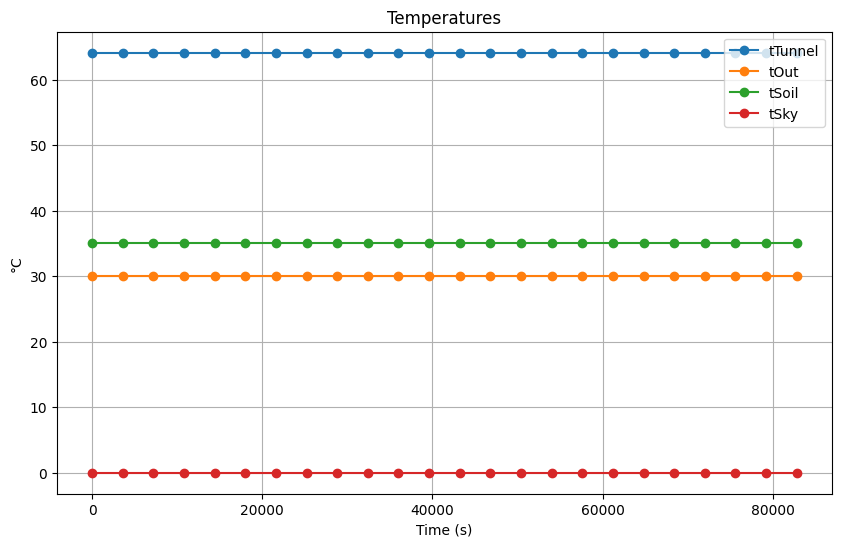

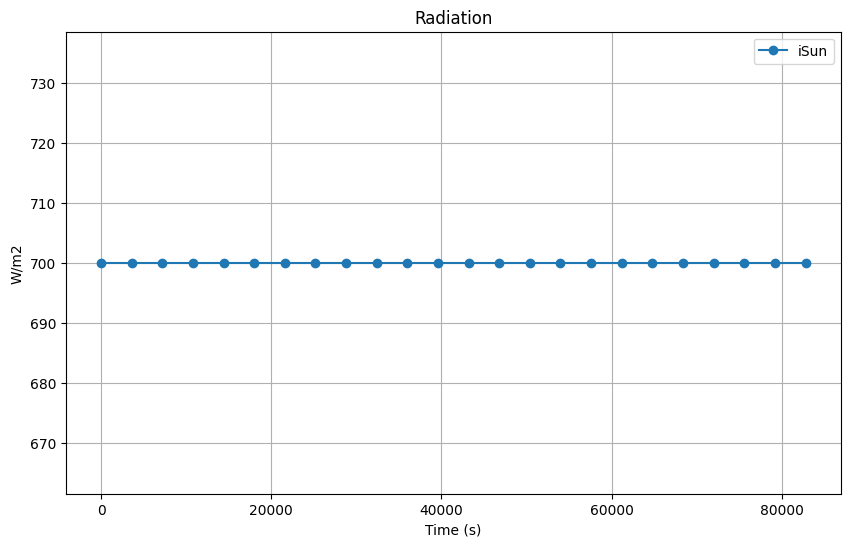

In [15]:
# Graph the simulated temperatures
display_graphs(mdl.full_sol, ["tTunnel", "tOut",  "tSoil", "tSky"],"Temperatures", "°C", '-o')

# Graph the solar radiation
display_graphs(mdl.full_sol, ["iSun"],"Radiation", "W/m2", '-o')

These graphs show constant values in time, like we saw in the output table. That will change soon.

Explanation of the output above

## 3.8 Adding variable weather input

Explain what's happening here, also document where the weather data is coming from

In [16]:
# New model
options = {
    "options": {
        "t_start":"0",
        "t_end": str(16 * 24 * 60 * 60),
        "output_step": "300",
        "t_eval": "300"
    }
}

tunnel_def["dummy"] = {
        "description": "Dummy variable",
        "unit": "-",
        "reference": "Used to get the model going",
        "type": "state",
        "definition": "0",
        "init": "0"
    }

mdl_2 = greenlight.GreenLight(
    base_path=os.getcwd(), 
    input_prompt=[tunnel_def, os.path.join("input", "example_weather.csv"), options], 
    output_path=os.path.join("output", "output_2.csv")
)
mdl_2.run()

NameError: name 'os' is not defined

In [ ]:
"""
Make graphs
"""

# Load simulation result
output_2 = pd.read_csv(os.path.join("output", "output_2.csv"), header=[0,1,2], low_memory=False)

display_output(output_2, [["tTunnel", "tOut",  "tSoil", "tSky"], ["iSun"]], ["Temperatures", "Radiation"], ["°C", "W/m2"], '-')
model_table(mdl_2)

### 3.8.1 Exercise: modifying the weather file

- Make a new weather file, modify it, run the sim with it

## Reflection

To do

## Next step

- Explain why this isn't good enough
- Save the def file for future use

In [ ]:
"""
Maybe not needed 
"""
def model_table(mdl):
    display(pd.DataFrame(mdl.variables.items(), columns=["Variable", "Definition"])
            .style
                .hide(axis="index")
                .set_properties(**{"text-align": "left", "font-family": "monospace"})
                .set_table_styles([
                    {"selector": "th", "props": [("text-align", "left")]}
              ])
        )

display_output(output_df, [["tTunnel", "tOut",  "tSoil", "tSky"], ["iSun"]], ["Temperatures", "Radiation"], ["°C", "W/m2"], '-o')
model_table(mdl)